# 第17步：批量有限影像特征与临床连接

182次目标扫描；只提取预先固定8项特征，不拟合模型或计算AUC。普通BraTS全部正标签并集称为源标注区域，标注盲法未确认。空间单位unknown，不推定mm或mL；uint8图像只能研究此公开派生版本。

In [1]:
from pathlib import Path
import sys,json
import numpy as np,pandas as pd
ROOT=Path.cwd()
if not (ROOT/'src').exists(): ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'src'))
from rn_public.ucsd_batch_features import run,FEATURES
summary=run(ROOT,download=False,workers=4)
print(json.dumps(summary,indent=2,ensure_ascii=False))

Cases processed 15/182; complete 15
Cases processed 30/182; complete 30
Cases processed 45/182; complete 45
Cases processed 60/182; complete 60
Cases processed 75/182; complete 75
Cases processed 90/182; complete 90
Cases processed 105/182; complete 105
Cases processed 120/182; complete 120
Cases processed 135/182; complete 135
Cases processed 150/182; complete 150
Cases processed 165/182; complete 165
Cases processed 180/182; complete 180
Cases processed 182/182; complete 182
{
  "checked_at_utc": "2026-10-29T08:04:07.537015+00:00",
  "clinical_timepoints": 238,
  "clinical_source_patients": 176,
  "target_timepoints": 182,
  "target_source_patients": 135,
  "target_files": 546,
  "declared_target_bytes": 525718739,
  "available_source_files": 546,
  "available_source_bytes": 525718739,
  "primary_complete_timepoints": 182,
  "primary_source_patients": 135,
  "primary_tumor_timepoints": 141,
  "primary_treatment_change_timepoints": 41,
  "target_failed_timepoints": 0,
  "not_listed_ti

源文件必须先恢复或下载。成功检查点绑定处理代码、协议和输入SHA256，再次使用前仍核对实际源文件。源文件缺失时不把已保存的特征缓存误认为本次提取成功。

In [2]:
out=ROOT/'reports/ucsd_batch_features'
cases=pd.read_csv(out/'all_clinical_case_status.csv')
files=pd.read_csv(out/'actual_file_QC.csv')
print(cases.groupby(['status','tumor_label']).agg(scans=('ID','size'),patients=('patient_id','nunique')))
assert len(cases)==238 and len(files)==546
print('Actual decoded files:',int(files.decoded.sum()))
print('Spatial units:',files.spatial_units.value_counts().to_dict())
print('Processing failures:',cases.loc[cases.status.eq('processing_failed'),['ID','error']].to_dict('records'))

                                          scans  patients
status                       tumor_label                 
complete                     0               41        29
                             1              141       114
not_listed_in_current_mirror 0               10        10
                             1               46        34
Actual decoded files: 546
Spatial units: {'unknown': 546}
Processing failures: []


In [3]:
primary=pd.read_csv(ROOT/'data/processed/ucsd_image_features.csv')
joined=pd.read_csv(ROOT/'data/processed/ucsd_clinical_image_features.csv')
assert list(primary.columns)==['ID',*FEATURES]
assert np.isfinite(primary[list(FEATURES)].to_numpy()).all()
assert primary.ID.is_unique and joined.ID.is_unique
assert set(primary.ID)==set(joined.ID)
print('Joined scans / source patients / validation groups:',len(joined),joined.patient_id.nunique(),joined.validation_group.nunique())
print('Clinical interval missing:',int(joined.initial_event_missing.sum()))
print('Labels (1=tumor, 0=treatment change):',joined.tumor_label.value_counts().to_dict())
print('Fixed MRI predictors:',list(FEATURES))

Joined scans / source patients / validation groups: 182 135 135
Clinical interval missing: 36
Labels (1=tumor, 0=treatment change): {1: 141, 0: 41}
Fixed MRI predictors: ['FLAIR_mean', 'FLAIR_std', 'FLAIR_entropy', 'FLAIR_glcm_contrast', 'T1post_mean', 'T1post_std', 'T1post_entropy', 'T1post_glcm_contrast']


一次6邻域腐蚀仅作边界敏感性分析。保持每图归一化参数与原ROI离散边界不变。下列分布不按类别筛选特征，不作显著性检验；重复扫描不是独立患者样本。

             feature  n_primary  n_eroded  median_absolute_relative_delta  max_absolute_relative_delta
          FLAIR_mean        182       182                        0.038652                     0.224408
           FLAIR_std        182       182                        0.046895                     0.228529
       FLAIR_entropy        182       182                        0.022268                     0.232482
 FLAIR_glcm_contrast        182       182                        0.152932                     0.588079
         T1post_mean        182       182                        0.028806                     0.294616
          T1post_std        182       182                        0.052124                     0.175275
      T1post_entropy        182       182                        0.012885                     0.109367
T1post_glcm_contrast        182       182                        0.068550                     0.381291


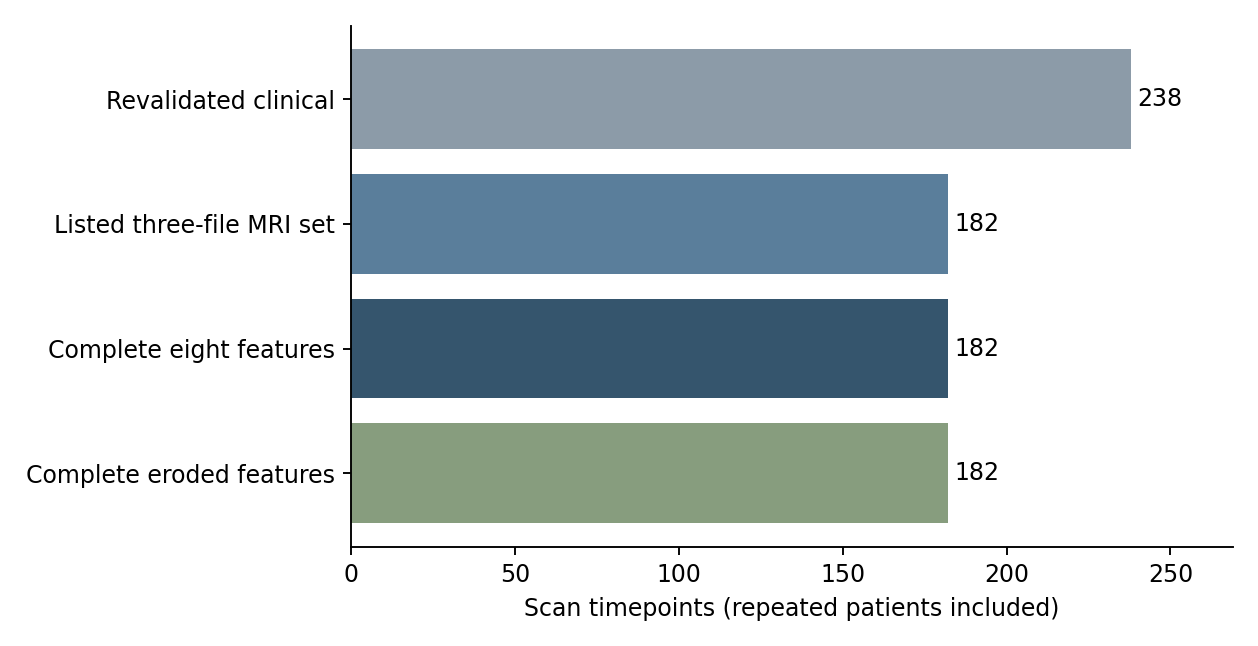

In [4]:
import importlib.util
spec=importlib.util.spec_from_file_location('batch_deliverables',ROOT/'scripts/make_ucsd_batch_deliverables.py')
module=importlib.util.module_from_spec(spec);spec.loader.exec_module(module)
stats=module.generate(ROOT,notebook=False)
print(stats[['feature','n_primary','n_eroded','median_absolute_relative_delta','max_absolute_relative_delta']].to_string(index=False))
from IPython.display import display,Image
display(Image(filename=str(ROOT/'figures/ucsd_batch_features/coverage.png')))
display(Image(filename=str(ROOT/'figures/ucsd_batch_features/boundary_deltas.png')))

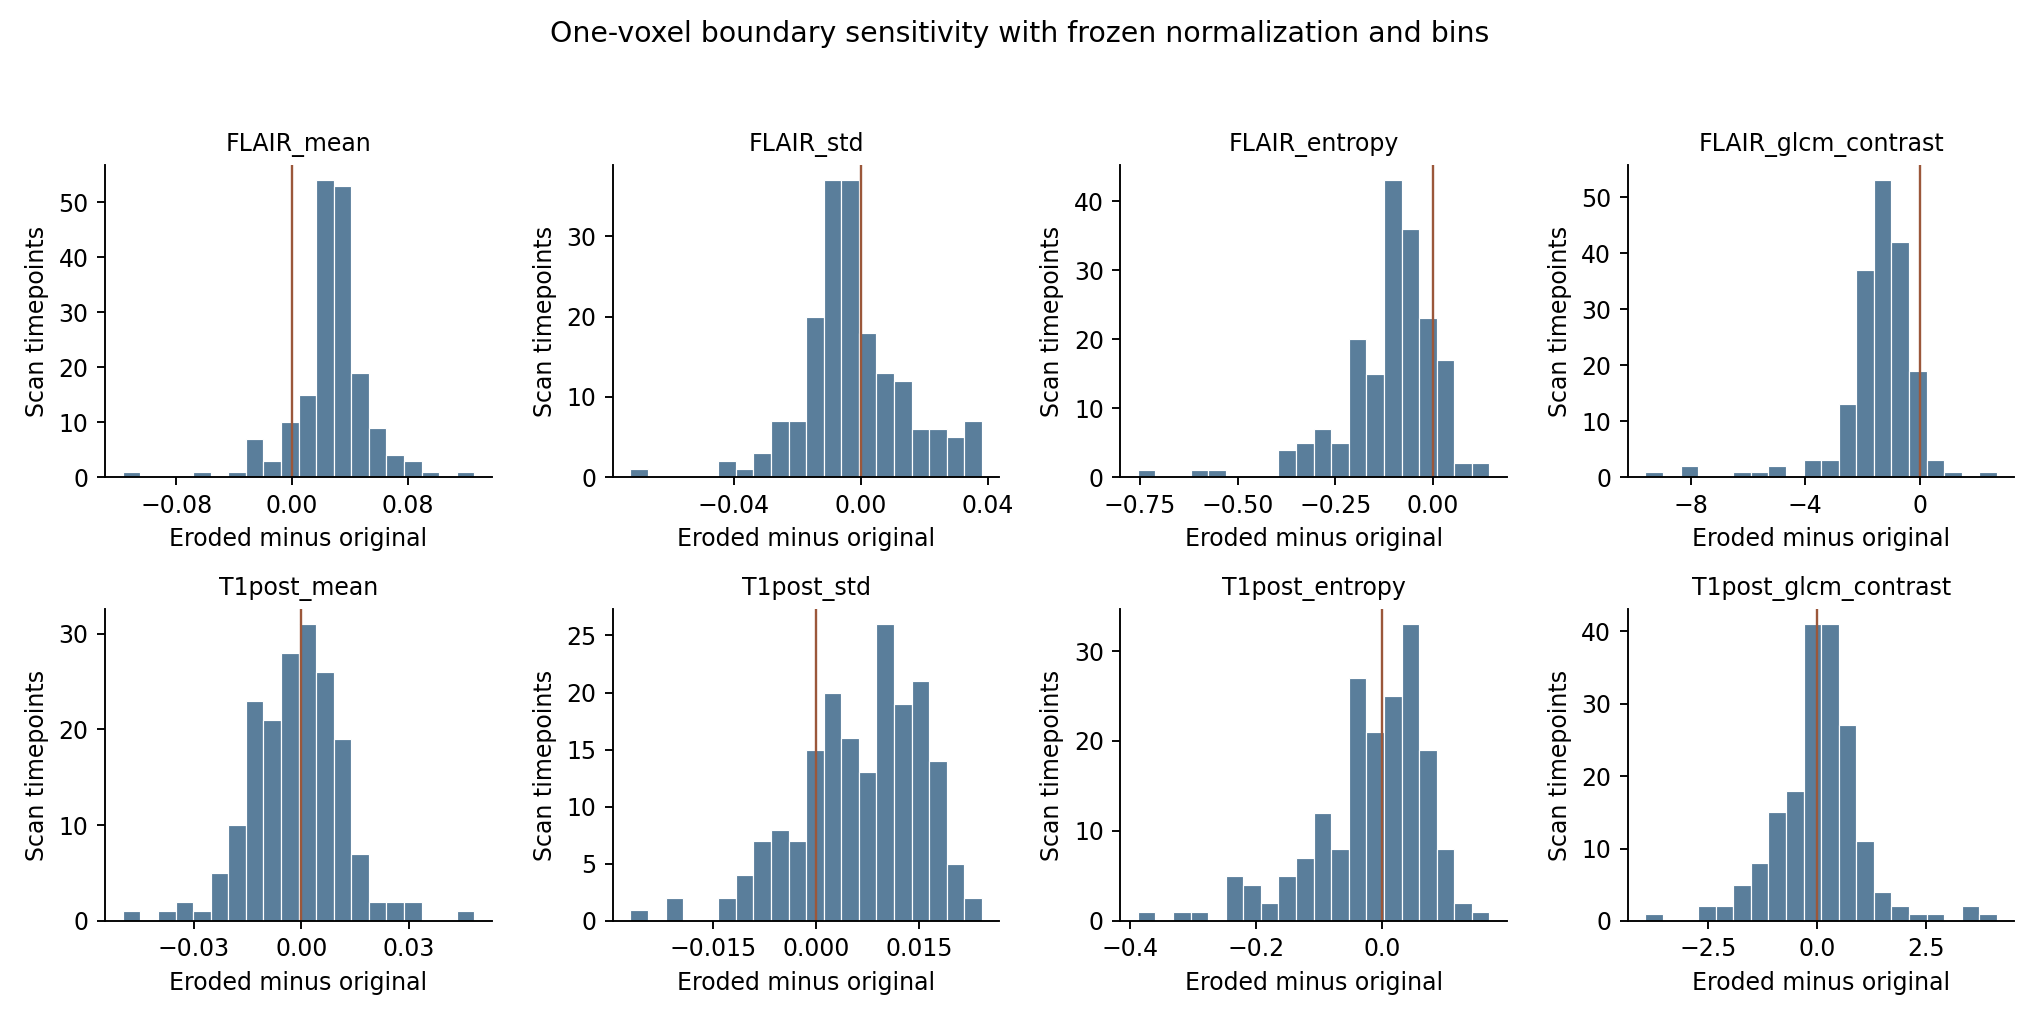

Protocol and code fingerprints verified. No MRI model fitted.
Next proposed stage: same-case clinical controls and limited penalized MRI fusion with patient-grouped validation, only after approval.


In [5]:
import hashlib
receipt=json.loads((out/'batch_receipt.json').read_text())
for p,expected in receipt['summary']['protocol_and_code_sha256'].items():
    assert hashlib.sha256((ROOT/p).read_bytes()).hexdigest()==expected
assert not summary['MRI_model_fitted'] and not summary['classification_metrics_computed']
print('Protocol and code fingerprints verified. No MRI model fitted.')
print('Next proposed stage: same-case clinical controls and limited penalized MRI fusion with patient-grouped validation, only after approval.')

下一步必须在共同影像病例上重建患者分组验证，临床对照也在相同病例/折重新估计。归一化之外的填补、标准化和任何特征处理只在训练折学习。不能把该子队列的新AUC与第13步238次扫描的旧AUC直接当作增益。